In [2]:
"""
CS3807 - Deep Learning Laboratory
Experiment 4: Comparative Study of Deep CNN Architectures Using Transfer Learning

Trains and compares 5 architectures on CIFAR-10:
  - LeNet-5     (trained from scratch  - no pretrained weights exist)
  - AlexNet     (trained from scratch  - no pretrained weights exist)
  - VGG16       (transfer learning, ImageNet weights)
  - GoogleNet   (InceptionV3 as the closest available Inception-family
                 model in keras.applications, transfer learning)
  - ResNet50    (transfer learning, ImageNet weights)

Run in Google Colab with a GPU runtime for reasonable training time.
"""

'\nCS3807 - Deep Learning Laboratory\nExperiment 4: Comparative Study of Deep CNN Architectures Using Transfer Learning\n\nTrains and compares 5 architectures on CIFAR-10:\n  - LeNet-5     (trained from scratch  - no pretrained weights exist)\n  - AlexNet     (trained from scratch  - no pretrained weights exist)\n  - VGG16       (transfer learning, ImageNet weights)\n  - GoogleNet   (InceptionV3 as the closest available Inception-family\n                 model in keras.applications, transfer learning)\n  - ResNet50    (transfer learning, ImageNet weights)\n\nRun in Google Colab with a GPU runtime for reasonable training time.\n'

In [3]:
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Conv2D, AveragePooling2D, MaxPooling2D, Flatten, Dense, Dropout,
    GlobalAveragePooling2D, BatchNormalization, Input
)
from tensorflow.keras.optimizers import Adam

from tensorflow.keras.applications import VGG16, ResNet50, InceptionV3
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

In [4]:
# ============================================================
# GLOBAL PLOT STYLE (applied to every figure in this script)
# ============================================================
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "DejaVu Serif"]
plt.rcParams["font.size"] = 15
plt.rcParams["figure.dpi"] = 600
plt.rcParams["savefig.dpi"] = 600


def save_fig(filename):
    """Save the current figure as a PDF with tight bounding box, then show it."""
    plt.savefig(filename, dpi=600, bbox_inches="tight")
    plt.show()


CLASS_NAMES = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

BATCH_SIZE = 32
EPOCHS_SCRATCH = 15          # LeNet-5 / AlexNet (trained from scratch)
EPOCHS_TL_FROZEN = 10        # Transfer learning, frozen base
EPOCHS_TL_FINETUNE = 5       # Transfer learning, fine-tuning phase


TASK 1: Dataset Preparation
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1625s 10us/step
Training data shape : (50000, 32, 32, 3)
Testing data shape  : (10000, 32, 32, 3)


/tmp/ipykernel_1865/1138497588.py:23: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.title(CLASS_NAMES[int(y_train[i])])


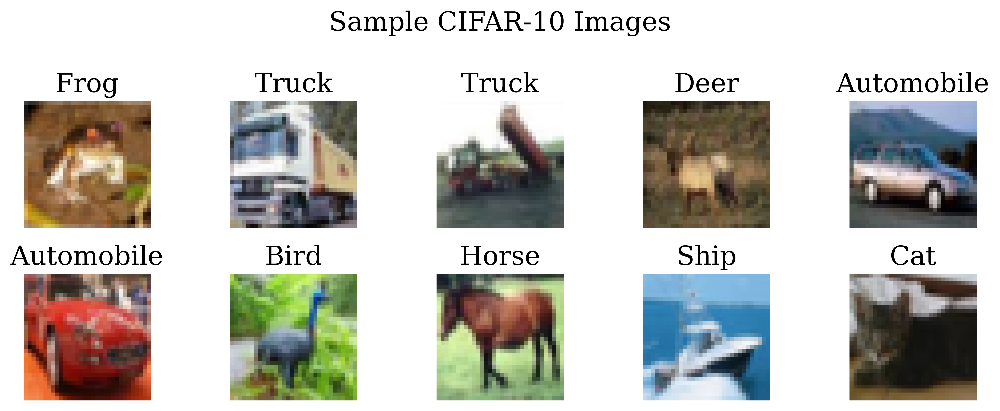

In [5]:
# ============================================================
# TASK 1: Dataset Preparation
# ============================================================
print("=" * 60)
print("TASK 1: Dataset Preparation")
print("=" * 60)

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

print("Training data shape :", x_train.shape)
print("Testing data shape  :", x_test.shape)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(CLASS_NAMES[int(y_train[i])])
    plt.axis('off')
plt.suptitle("Sample CIFAR-10 Images")
plt.tight_layout()
save_fig("sample_images.pdf")


In [6]:
# ============================================================
# Helper: build a tf.data pipeline for a given model
# ============================================================
def make_dataset(x, y_cat, batch_size, resize_to=None, preprocess_fn=None,
                  shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y_cat))
    if shuffle:
        ds = ds.shuffle(buffer_size=10000)

    def _map(img, label):
        img = img * 255.0  # back to 0-255 for keras preprocess_input fns
        if resize_to is not None:
            img = tf.image.resize(img, resize_to)
        if preprocess_fn is not None:
            img = preprocess_fn(img)
        else:
            img = img / 255.0
        return img, label

    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


In [7]:
# ============================================================
# Model builders
# ============================================================
def build_lenet5():
    model = Sequential([
        Input(shape=(32, 32, 3)),
        Conv2D(6, (5, 5), activation='relu', padding='same'),
        AveragePooling2D(pool_size=(2, 2)),
        Conv2D(16, (5, 5), activation='relu'),
        AveragePooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(120, activation='relu'),
        Dense(84, activation='relu'),
        Dense(10, activation='softmax')
    ], name="LeNet-5")
    return model

def build_alexnet():
    model = Sequential([
        Input(shape=(32, 32, 3)),
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(192, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(384, (3, 3), activation='relu', padding='same'),
        Conv2D(256, (3, 3), activation='relu', padding='same'),
        Conv2D(256, (3, 3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(1024, activation='relu'),
        Dropout(0.5),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(10, activation='softmax')
    ], name="AlexNet")
    return model

def build_transfer_model(base_ctor, input_shape, last_block_prefix):
    base_model = base_ctor(weights='imagenet', include_top=False,
                            input_shape=input_shape)
    base_model.trainable = False
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(256, activation='relu')(x)
    output = Dense(10, activation='softmax')(x)
    model = Model(inputs=base_model.input, outputs=output)
    return model, base_model, last_block_prefix


In [8]:

# ============================================================
# Model configuration table
# ============================================================
MODEL_CONFIGS = {
    "LeNet-5": {
        "type": "scratch",
        "input_size": (32, 32),
        "preprocess_fn": None,
    },
    "AlexNet": {
        "type": "scratch",
        "input_size": (32, 32),
        "preprocess_fn": None,
    },
    "VGG16": {
        "type": "transfer",
        "input_size": (32, 32),
        "preprocess_fn": vgg16_preprocess,
        "base_ctor": VGG16,
        "last_block_prefix": "block5",
    },

    "GoogleNet": {
        "type": "transfer",
        "input_size": (75, 75),   # InceptionV3 minimum input size
        "preprocess_fn": inception_preprocess,
        "base_ctor": InceptionV3,
        "last_block_prefix": "mixed10",
    },
    "ResNet50": {
        "type": "transfer",
        "input_size": (32, 32),
        "preprocess_fn": resnet50_preprocess,
        "base_ctor": ResNet50,
        "last_block_prefix": "conv5_block3",
    },
}



TRAINING: LeNet-5
Epoch 1/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - accuracy: 0.4147 - loss: 1.6133 - val_accuracy: 0.5052 - val_loss: 1.3868
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.5291 - loss: 1.3177 - val_accuracy: 0.5554 - val_loss: 1.2630
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5757 - loss: 1.1979 - val_accuracy: 0.5764 - val_loss: 1.1902
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6025 - loss: 1.1213 - val_accuracy: 0.5914 - val_loss: 1.1632
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6251 - loss: 1.0556 - val_accuracy: 0.6037 - val_loss: 1.1125
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.6470 - loss: 0.9986 - val_accuracy: 0.6178 - val_loss: 1.0929
Epoch 7/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6659 - loss: 0.9474 - val_accuracy: 0.5956 - val_loss: 1.1386
Epoch 8/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6

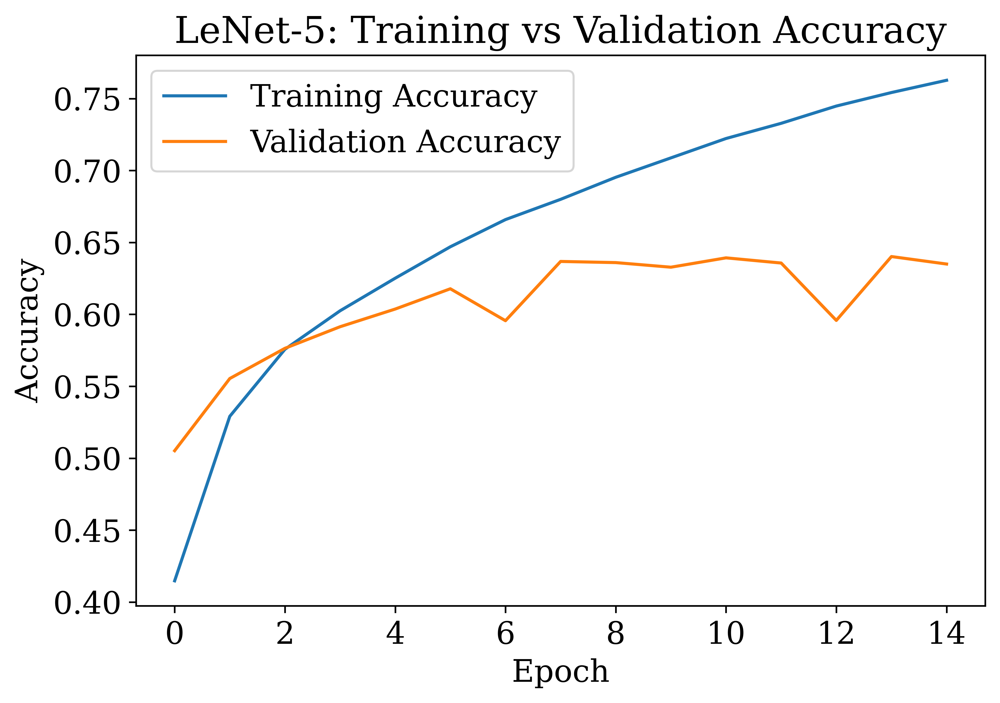

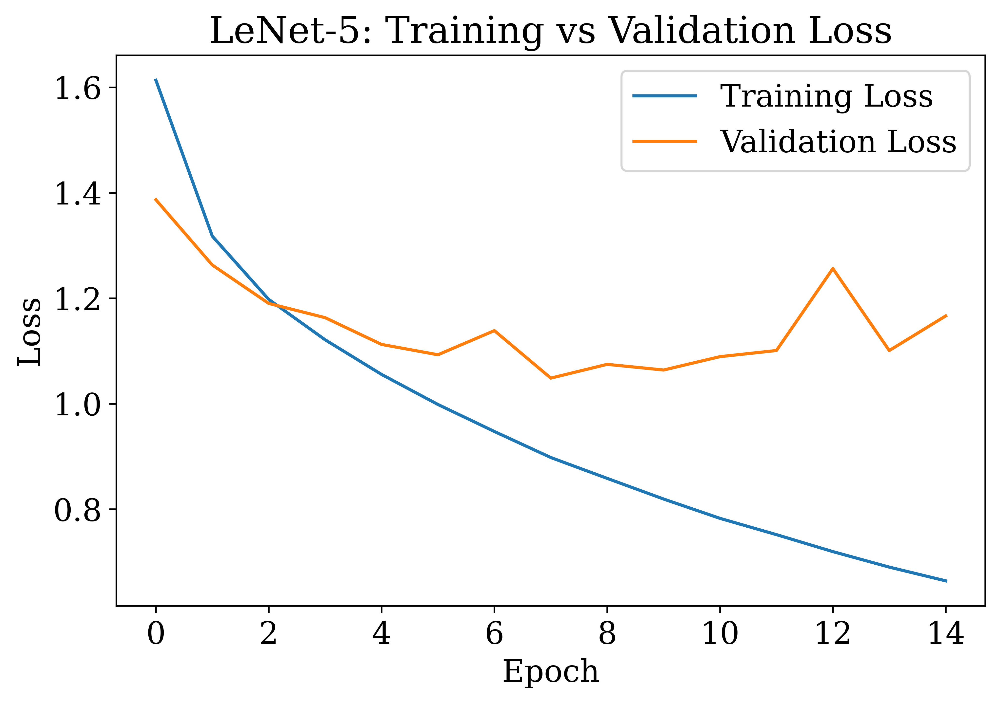

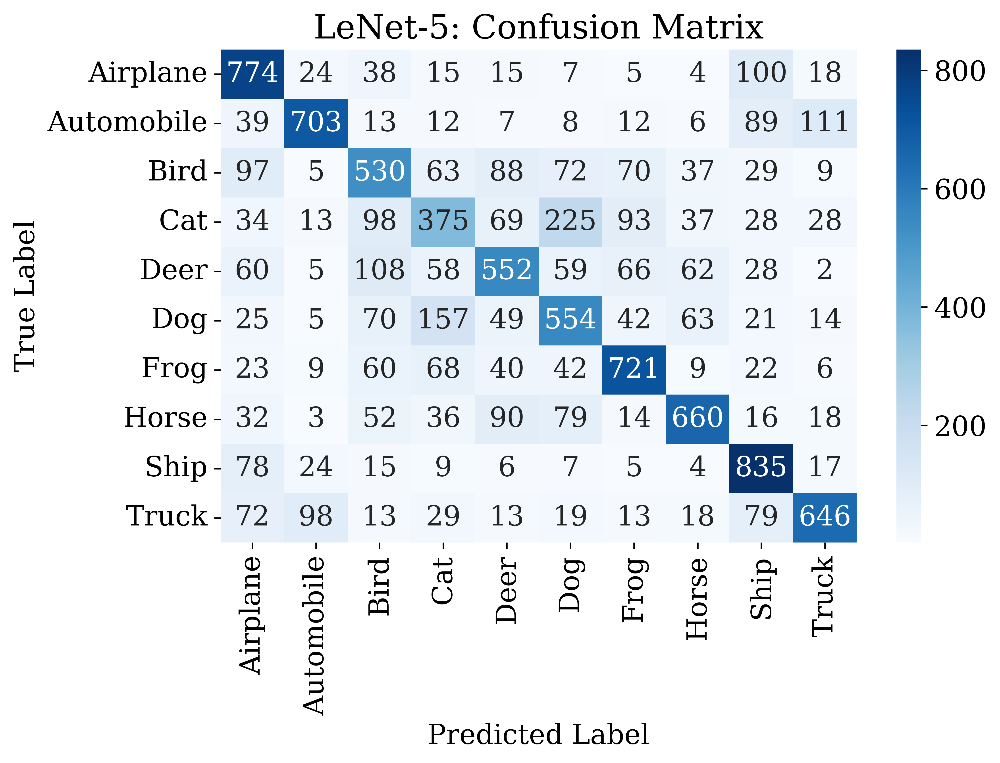


Classification Report - LeNet-5:
              precision    recall  f1-score   support

    Airplane       0.63      0.77      0.69      1000
  Automobile       0.79      0.70      0.74      1000
        Bird       0.53      0.53      0.53      1000
         Cat       0.46      0.38      0.41      1000
        Deer       0.59      0.55      0.57      1000
         Dog       0.52      0.55      0.53      1000
        Frog       0.69      0.72      0.71      1000
       Horse       0.73      0.66      0.69      1000
        Ship       0.67      0.83      0.74      1000
       Truck       0.74      0.65      0.69      1000

    accuracy                           0.64     10000
   macro avg       0.64      0.64      0.63     10000
weighted avg       0.64      0.64      0.63     10000


TRAINING: AlexNet
Epoch 1/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 18ms/step - accuracy: 0.4483 - loss: 1.5284 - val_accuracy: 0.4932 - val_loss: 1.4763
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 13ms/step 

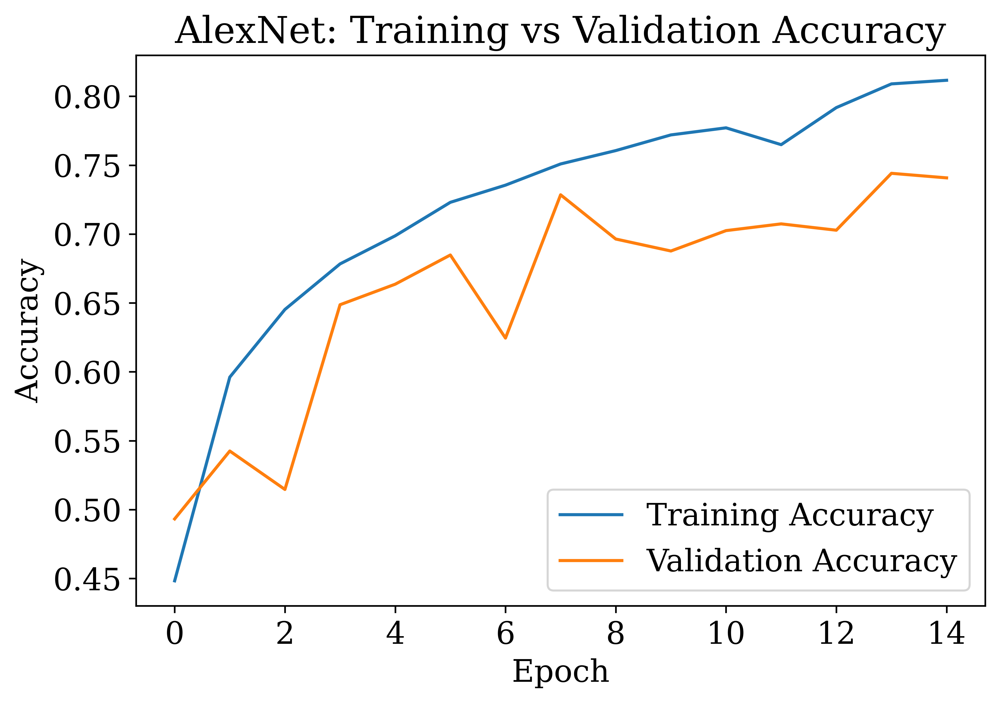

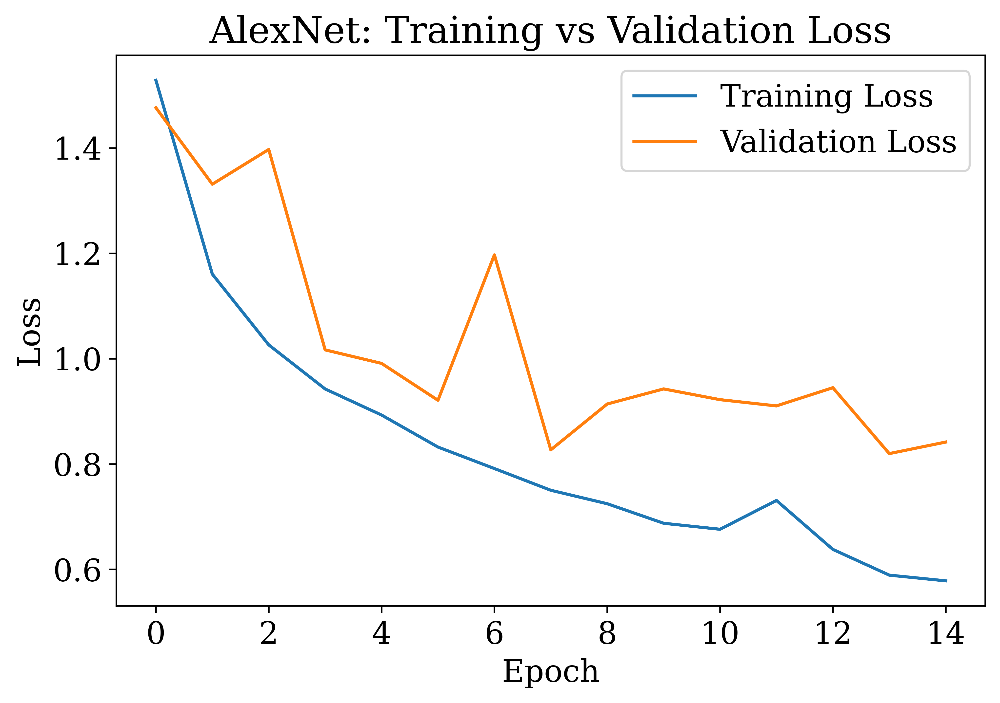

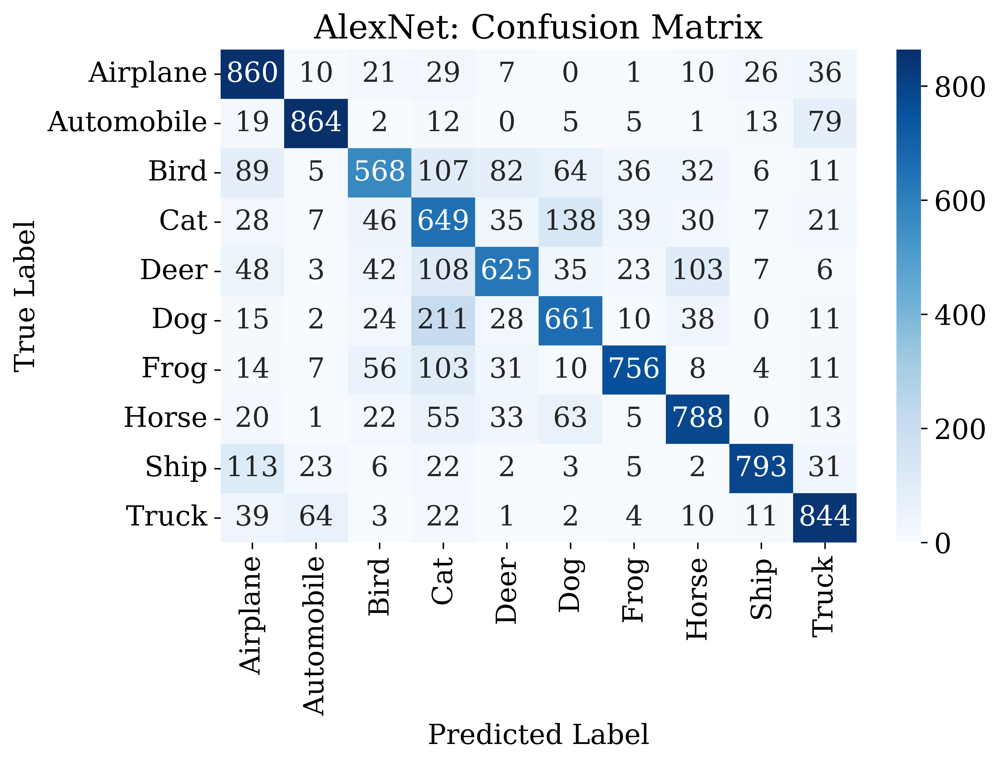


Classification Report - AlexNet:
              precision    recall  f1-score   support

    Airplane       0.69      0.86      0.77      1000
  Automobile       0.88      0.86      0.87      1000
        Bird       0.72      0.57      0.63      1000
         Cat       0.49      0.65      0.56      1000
        Deer       0.74      0.62      0.68      1000
         Dog       0.67      0.66      0.67      1000
        Frog       0.86      0.76      0.80      1000
       Horse       0.77      0.79      0.78      1000
        Ship       0.91      0.79      0.85      1000
       Truck       0.79      0.84      0.82      1000

    accuracy                           0.74     10000
   macro avg       0.75      0.74      0.74     10000
weighted avg       0.75      0.74      0.74     10000


TRAINING: VGG16
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.5661 - loss: 1.9275 - val_accuracy: 0.6247 - val_loss: 1.1042
Epoch 2

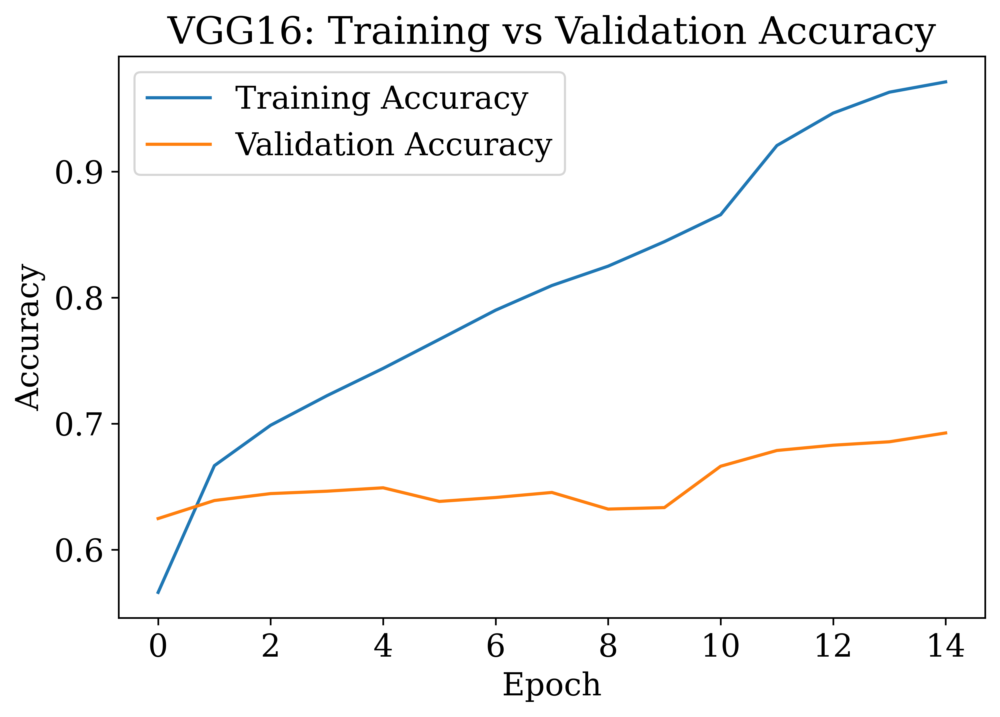

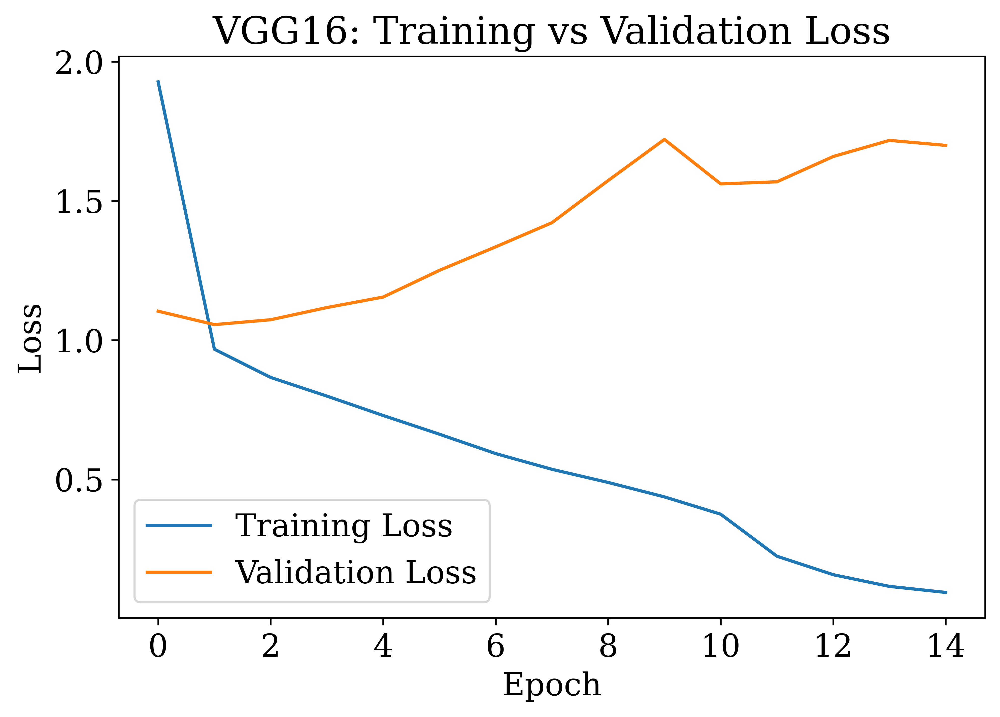

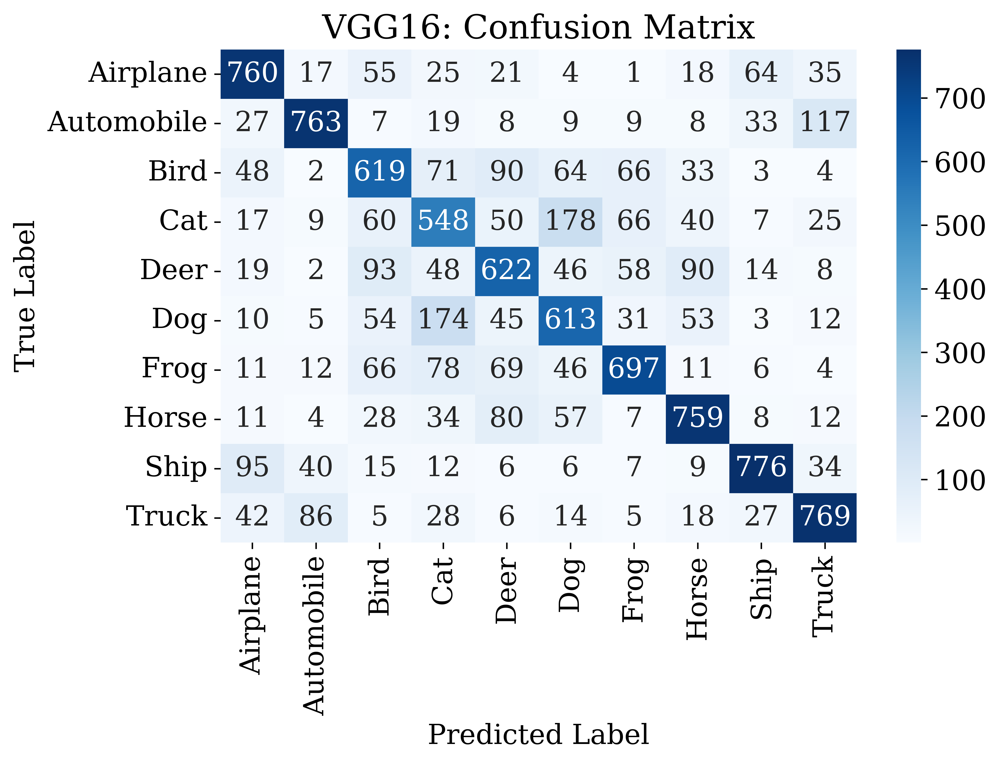


Classification Report - VGG16:
              precision    recall  f1-score   support

    Airplane       0.73      0.76      0.75      1000
  Automobile       0.81      0.76      0.79      1000
        Bird       0.62      0.62      0.62      1000
         Cat       0.53      0.55      0.54      1000
        Deer       0.62      0.62      0.62      1000
         Dog       0.59      0.61      0.60      1000
        Frog       0.74      0.70      0.72      1000
       Horse       0.73      0.76      0.74      1000
        Ship       0.82      0.78      0.80      1000
       Truck       0.75      0.77      0.76      1000

    accuracy                           0.69     10000
   macro avg       0.69      0.69      0.69     10000
weighted avg       0.69      0.69      0.69     10000


TRAINING: GoogleNet
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 35ms/step - accuracy: 0.6068 - loss: 1.1268 - val_accuracy: 0.6411 - val_loss: 1.0283
Epoch

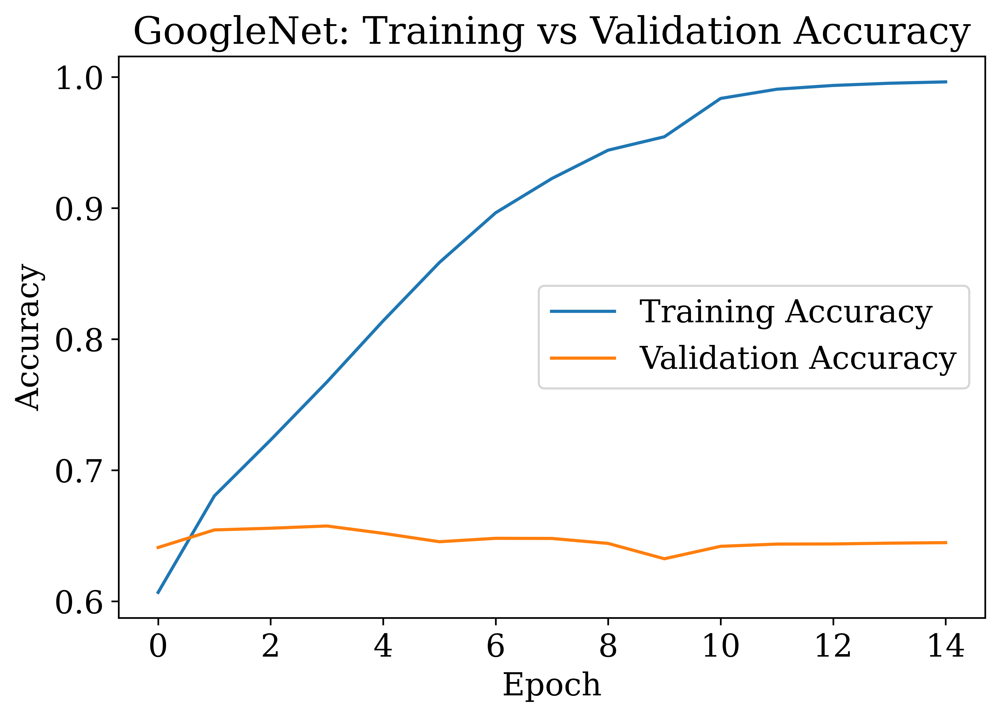

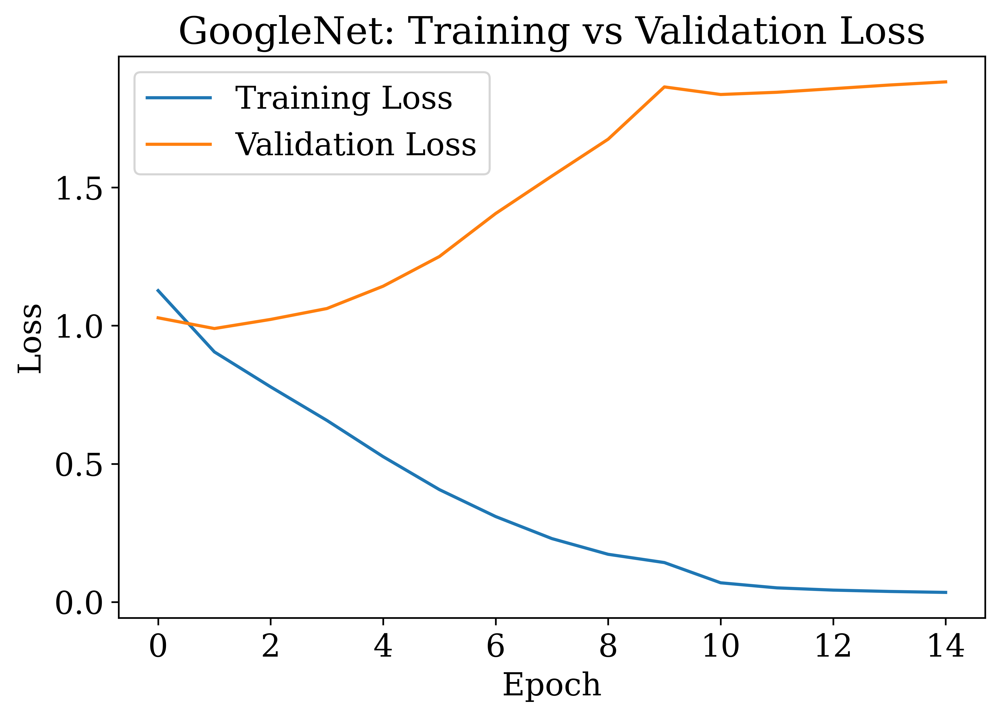

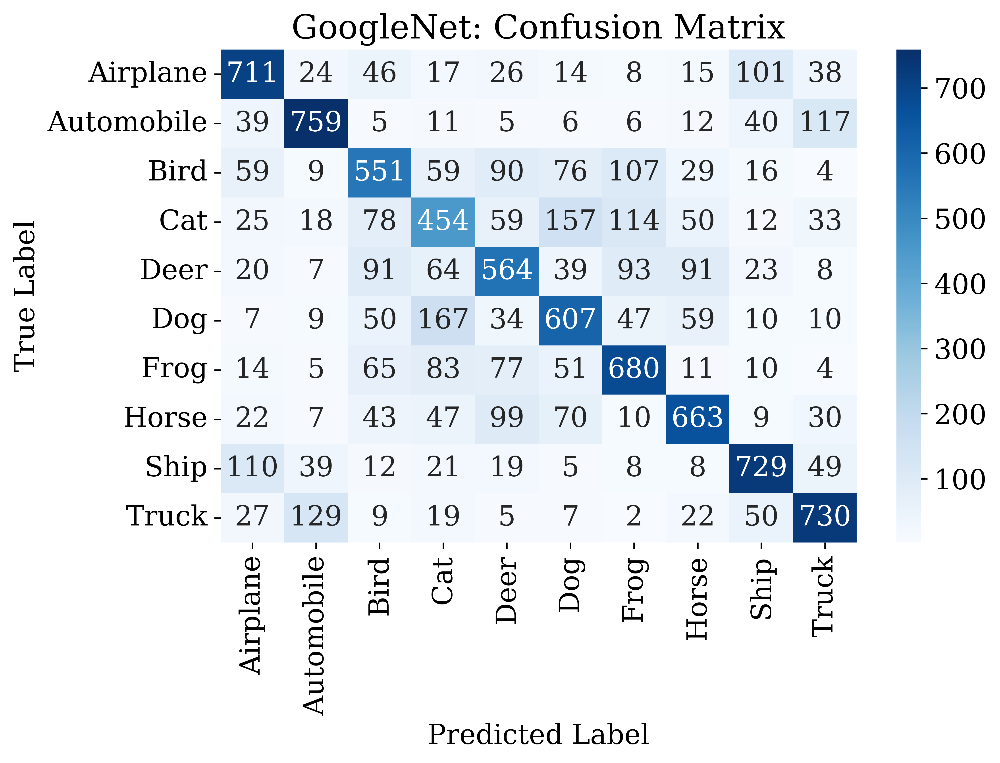


Classification Report - GoogleNet:
              precision    recall  f1-score   support

    Airplane       0.69      0.71      0.70      1000
  Automobile       0.75      0.76      0.76      1000
        Bird       0.58      0.55      0.57      1000
         Cat       0.48      0.45      0.47      1000
        Deer       0.58      0.56      0.57      1000
         Dog       0.59      0.61      0.60      1000
        Frog       0.63      0.68      0.66      1000
       Horse       0.69      0.66      0.68      1000
        Ship       0.73      0.73      0.73      1000
       Truck       0.71      0.73      0.72      1000

    accuracy                           0.64     10000
   macro avg       0.64      0.64      0.64     10000
weighted avg       0.64      0.64      0.64     10000


TRAINING: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 57s 29ms/step - accuracy: 0.6074 - loss: 1.1611 - val_accuracy: 0.6425 - val_loss: 1.0282
Ep

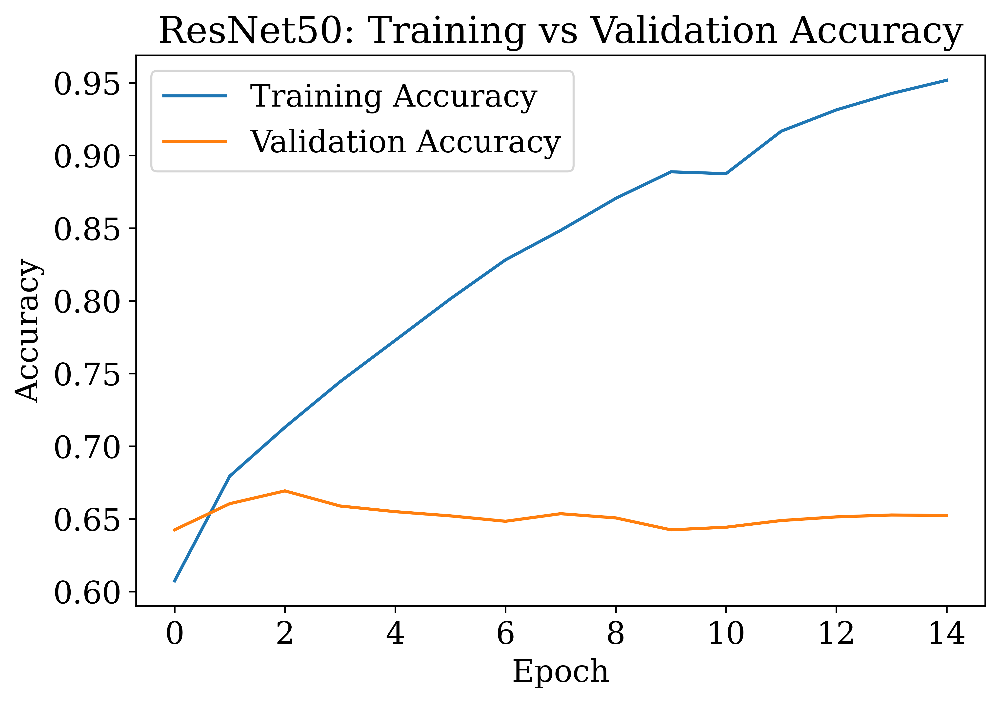

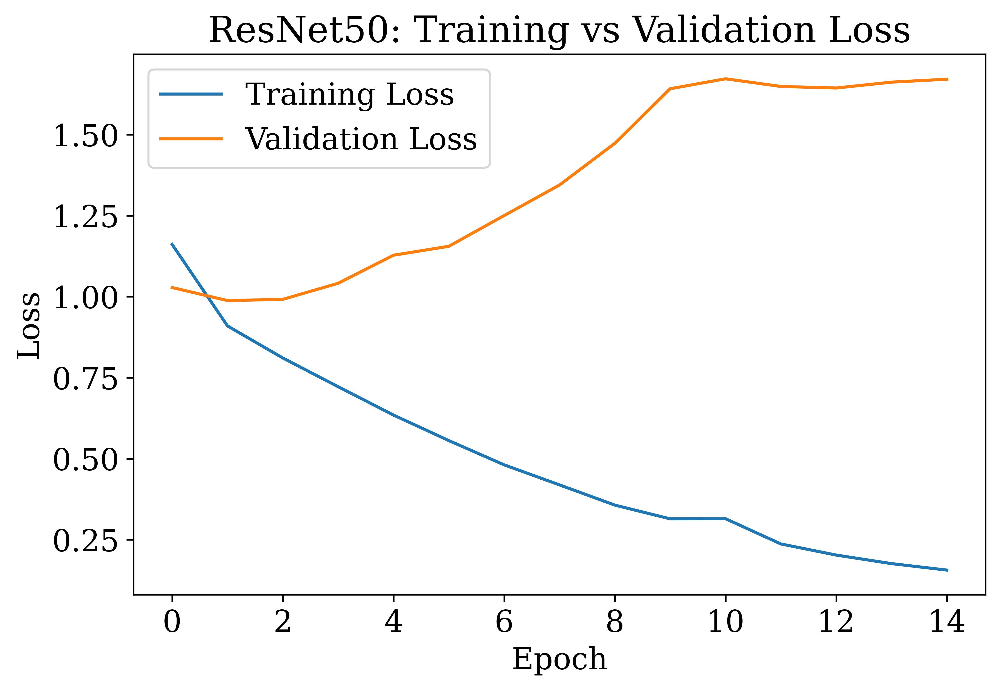

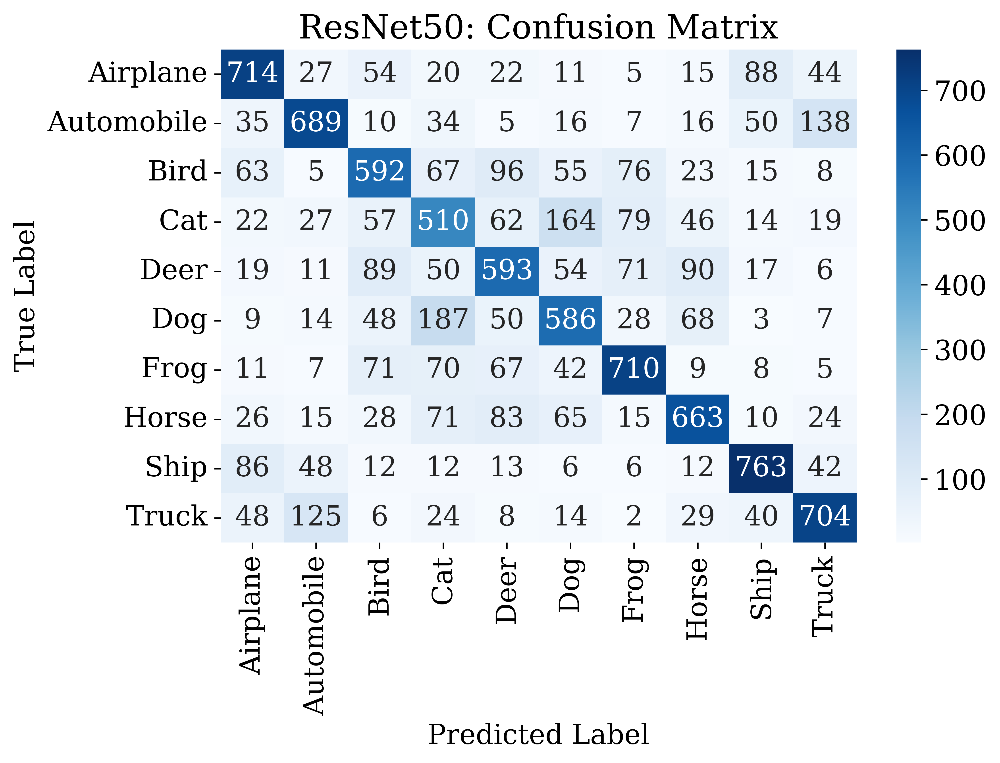


Classification Report - ResNet50:
              precision    recall  f1-score   support

    Airplane       0.69      0.71      0.70      1000
  Automobile       0.71      0.69      0.70      1000
        Bird       0.61      0.59      0.60      1000
         Cat       0.49      0.51      0.50      1000
        Deer       0.59      0.59      0.59      1000
         Dog       0.58      0.59      0.58      1000
        Frog       0.71      0.71      0.71      1000
       Horse       0.68      0.66      0.67      1000
        Ship       0.76      0.76      0.76      1000
       Truck       0.71      0.70      0.71      1000

    accuracy                           0.65     10000
   macro avg       0.65      0.65      0.65     10000
weighted avg       0.65      0.65      0.65     10000



In [9]:

# ============================================================
# Train + evaluate every model
# ============================================================
results = {}

for model_name, cfg in MODEL_CONFIGS.items():
    print("\n" + "=" * 60)
    print(f"TRAINING: {model_name}")
    print("=" * 60)

    resize_to = cfg["input_size"] if cfg["input_size"] != (32, 32) else None
    train_ds = make_dataset(x_train, y_train_cat, BATCH_SIZE,
                             resize_to=resize_to,
                             preprocess_fn=cfg["preprocess_fn"], shuffle=True)
    test_ds = make_dataset(x_test, y_test_cat, BATCH_SIZE,
                            resize_to=resize_to,
                            preprocess_fn=cfg["preprocess_fn"])

    full_acc, full_val_acc, full_loss, full_val_loss = [], [], [], []
    start_time = time.time()

    if cfg["type"] == "scratch":
        model = build_lenet5() if model_name == "LeNet-5" else build_alexnet()
        model.compile(optimizer=Adam(learning_rate=0.001),
                      loss='categorical_crossentropy', metrics=['accuracy'])
        history = model.fit(train_ds, validation_data=test_ds,
                             epochs=EPOCHS_SCRATCH)
        full_acc = history.history['accuracy']
        full_val_acc = history.history['val_accuracy']
        full_loss = history.history['loss']
        full_val_loss = history.history['val_loss']

    else:  # transfer learning: frozen phase + fine-tune phase
        input_shape = (cfg["input_size"][0], cfg["input_size"][1], 3)
        model, base_model, last_block_prefix = build_transfer_model(
            cfg["base_ctor"], input_shape, cfg["last_block_prefix"])

        model.compile(optimizer=Adam(learning_rate=0.001),
                      loss='categorical_crossentropy', metrics=['accuracy'])
        history1 = model.fit(train_ds, validation_data=test_ds,
                              epochs=EPOCHS_TL_FROZEN)

        # Fine-tune: unfreeze last block only
        base_model.trainable = True
        for layer in base_model.layers:
            if last_block_prefix not in layer.name:
                layer.trainable = False

        model.compile(optimizer=Adam(learning_rate=1e-5),
                      loss='categorical_crossentropy', metrics=['accuracy'])
        history2 = model.fit(train_ds, validation_data=test_ds,
                              epochs=EPOCHS_TL_FINETUNE)

        full_acc = history1.history['accuracy'] + history2.history['accuracy']
        full_val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
        full_loss = history1.history['loss'] + history2.history['loss']
        full_val_loss = history1.history['val_loss'] + history2.history['val_loss']

    train_time = time.time() - start_time

    # ---- Evaluation ----
    y_pred_probs = model.predict(test_ds)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = y_test.flatten()

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    total_params = model.count_params()

    results[model_name] = {
        "accuracy": acc, "precision": prec, "recall": rec, "f1": f1,
        "train_time": train_time, "params": total_params, "cm": cm,
        "acc_curve": full_acc, "val_acc_curve": full_val_acc,
        "loss_curve": full_loss, "val_loss_curve": full_val_loss,
    }

    print(f"{model_name} -> Acc: {acc:.4f}, Precision: {prec:.4f}, "
          f"Recall: {rec:.4f}, F1: {f1:.4f}, Time: {train_time:.1f}s, "
          f"Params: {total_params:,}")

    # ---- Per-model plots ----
    plt.figure(figsize=(7, 5))
    plt.plot(full_acc, label='Training Accuracy')
    plt.plot(full_val_acc, label='Validation Accuracy')
    plt.title(f'{model_name}: Training vs Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.tight_layout()
    save_fig(f"{model_name.lower().replace(' ', '_')}_accuracy_curve.pdf")

    plt.figure(figsize=(7, 5))
    plt.plot(full_loss, label='Training Loss')
    plt.plot(full_val_loss, label='Validation Loss')
    plt.title(f'{model_name}: Training vs Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.tight_layout()
    save_fig(f"{model_name.lower().replace(' ', '_')}_loss_curve.pdf")

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'{model_name}: Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    save_fig(f"{model_name.lower().replace(' ', '_')}_confusion_matrix.pdf")

    print(f"\nClassification Report - {model_name}:")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                                 zero_division=0))




Generating Cross-Model Comparison Plots


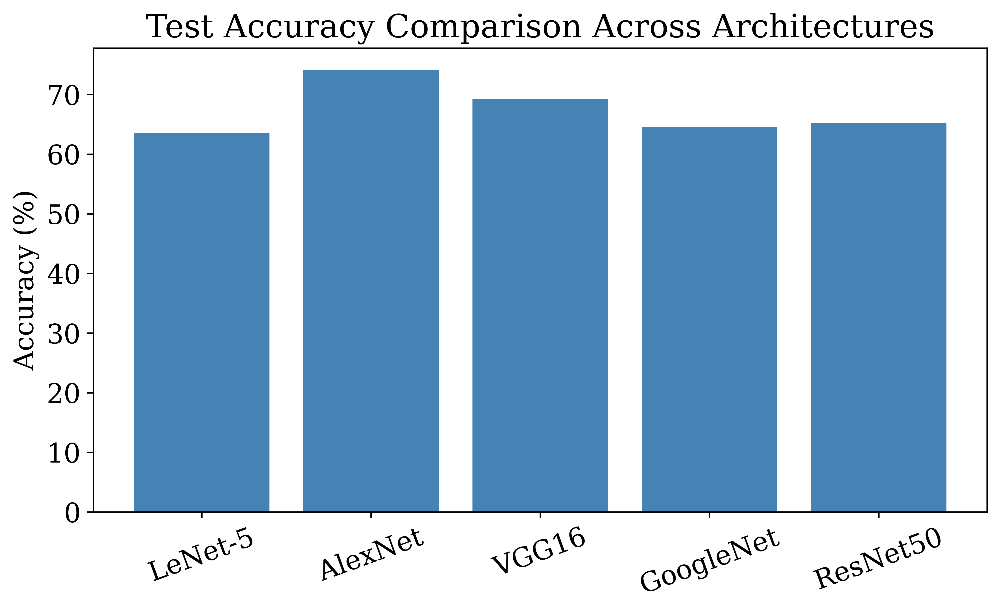

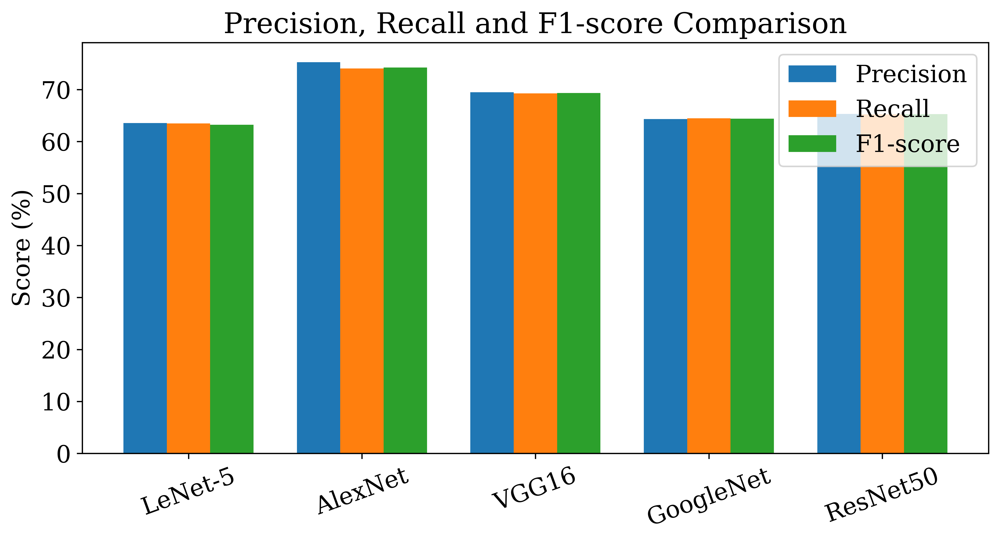

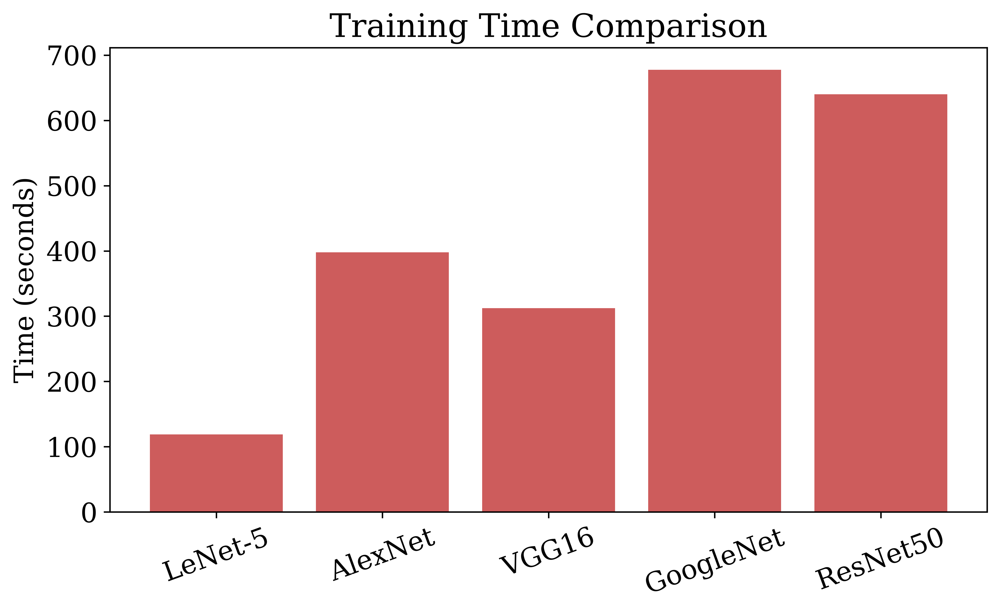

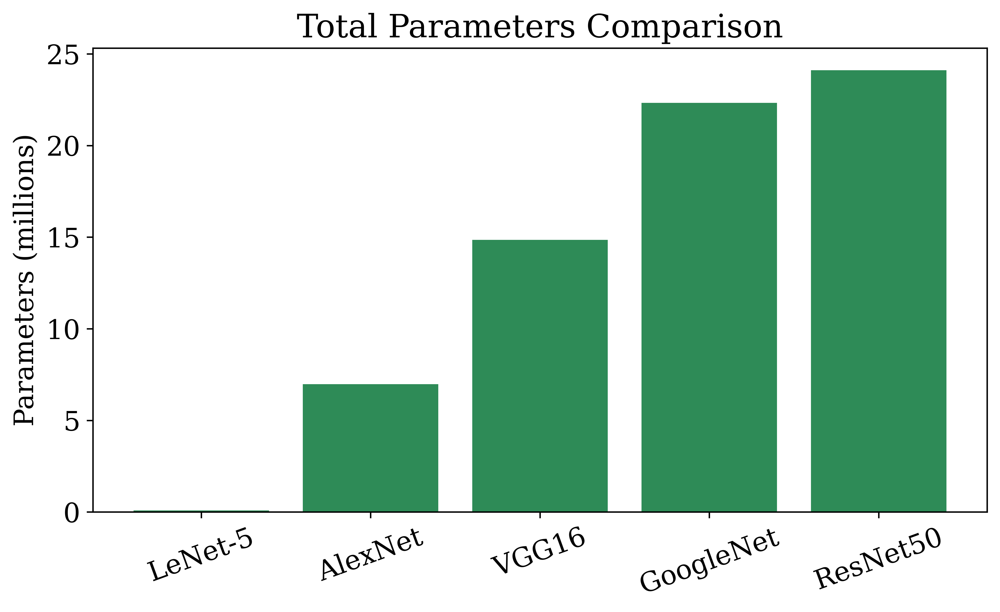

In [10]:
# ============================================================
# COMPARISON PLOTS ACROSS ALL 5 MODELS
# ============================================================
print("\n" + "=" * 60)
print("Generating Cross-Model Comparison Plots")
print("=" * 60)

model_names = list(results.keys())
accuracies = [results[m]["accuracy"] * 100 for m in model_names]
precisions = [results[m]["precision"] * 100 for m in model_names]
recalls = [results[m]["recall"] * 100 for m in model_names]
f1_scores = [results[m]["f1"] * 100 for m in model_names]
train_times = [results[m]["train_time"] for m in model_names]
param_counts = [results[m]["params"] / 1e6 for m in model_names]  # millions

# Accuracy comparison
plt.figure(figsize=(8, 5))
plt.bar(model_names, accuracies, color='steelblue')
plt.title('Test Accuracy Comparison Across Architectures')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=20)
plt.tight_layout()
save_fig("comparison_accuracy.pdf")

# Precision / Recall / F1 grouped comparison
x = np.arange(len(model_names))
width = 0.25
plt.figure(figsize=(9, 5))
plt.bar(x - width, precisions, width, label='Precision')
plt.bar(x, recalls, width, label='Recall')
plt.bar(x + width, f1_scores, width, label='F1-score')
plt.xticks(x, model_names, rotation=20)
plt.ylabel('Score (%)')
plt.title('Precision, Recall and F1-score Comparison')
plt.legend()
plt.tight_layout()
save_fig("comparison_precision_recall_f1.pdf")

# Training time comparison
plt.figure(figsize=(8, 5))
plt.bar(model_names, train_times, color='indianred')
plt.title('Training Time Comparison')
plt.ylabel('Time (seconds)')
plt.xticks(rotation=20)
plt.tight_layout()
save_fig("comparison_training_time.pdf")

# Parameter count comparison
plt.figure(figsize=(8, 5))
plt.bar(model_names, param_counts, color='seagreen')
plt.title('Total Parameters Comparison')
plt.ylabel('Parameters (millions)')
plt.xticks(rotation=20)
plt.tight_layout()
save_fig("comparison_parameters.pdf")


In [11]:
# ============================================================
# FINAL RESULTS TABLE (fills Section 18.2 of the report)
# ============================================================
print("\n" + "=" * 70)
print("FINAL COMPARISON TABLE")
print("=" * 70)
header = f"{'Model':<12}{'Params (M)':<14}{'Accuracy (%)':<15}{'Time (s)':<12}"
print(header)
print("-" * len(header))
for m in model_names:
    r = results[m]
    print(f"{m:<12}{r['params']/1e6:<14.2f}{r['accuracy']*100:<15.2f}{r['train_time']:<12.1f}")


FINAL COMPARISON TABLE
Model       Params (M)    Accuracy (%)   Time (s)    
-----------------------------------------------------
LeNet-5     0.08          63.50          118.7       
AlexNet     6.98          74.08          397.8       
VGG16       14.85         69.26          312.3       
GoogleNet   22.33         64.48          677.6       
ResNet50    24.11         65.24          640.1       


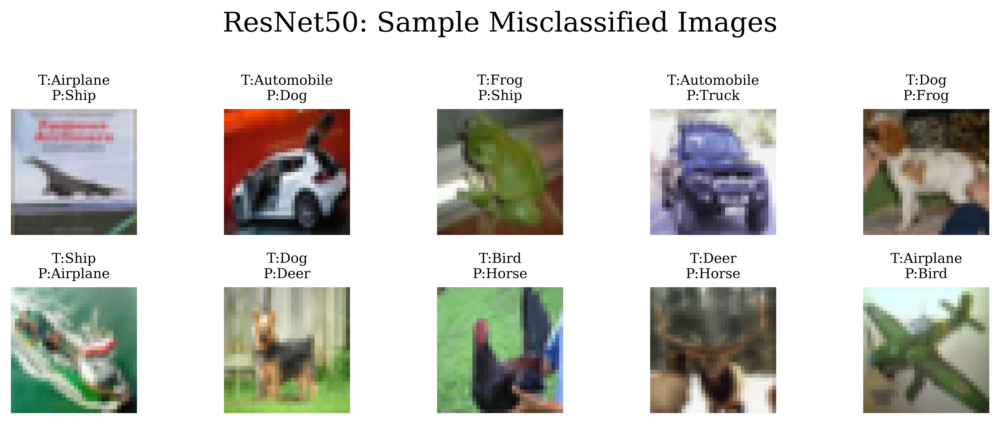

In [12]:
    # ---- Misclassified images ----
    misclassified_idx = np.where(y_pred != y_true)[0]
    plt.figure(figsize=(10, 4))
    for i, idx in enumerate(misclassified_idx[:10]):
        plt.subplot(2, 5, i + 1)
        plt.imshow(x_test[idx])
        plt.title(f"T:{CLASS_NAMES[y_true[idx]]}\nP:{CLASS_NAMES[y_pred[idx]]}",
                   fontsize=9)
        plt.axis('off')
    plt.suptitle(f'{model_name}: Sample Misclassified Images')
    plt.tight_layout()
    save_fig(f"{model_name.lower().replace(' ', '_')}_misclassified_images.pdf")


HYPERPARAMETER STUDY

Config: {'lr': 0.001, 'batch_size': 32, 'optimizer': 'adam', 'dense_units': 256}
Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.5680 - loss: 1.8627 - val_accuracy: 0.6200 - val_loss: 1.1068
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.6645 - loss: 0.9669 - val_accuracy: 0.6406 - val_loss: 1.0816
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.6947 - loss: 0.8742 - val_accuracy: 0.6423 - val_loss: 1.1016
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7158 - loss: 0.8112 - val_accuracy: 0.6503 - val_loss: 1.1007
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7387 - loss: 0.7421 - val_accuracy: 0.6444 - val_loss: 1.1739
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - accuracy: 0.7619 - loss: 0.6724 - val_accuracy: 0.6388 - val_loss: 1.2655
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.7837 - loss: 0.6089 - val_accuracy

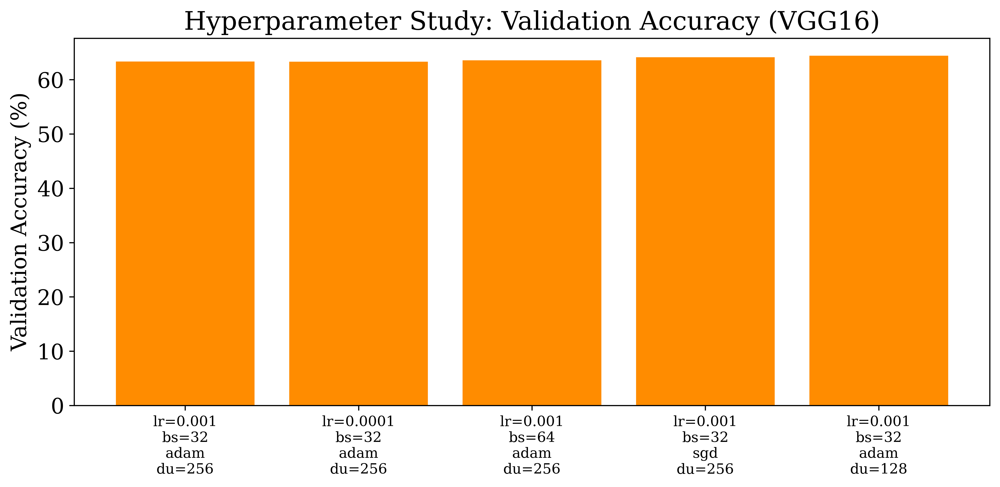


Hyperparameter Study Results:
{'lr': 0.001, 'batch_size': 32, 'optimizer': 'adam', 'dense_units': 256, 'val_accuracy': 0.6334999799728394, 'train_time': 189.10228776931763}
{'lr': 0.0001, 'batch_size': 32, 'optimizer': 'adam', 'dense_units': 256, 'val_accuracy': 0.6331999897956848, 'train_time': 168.54975724220276}
{'lr': 0.001, 'batch_size': 64, 'optimizer': 'adam', 'dense_units': 256, 'val_accuracy': 0.635699987411499, 'train_time': 130.62277579307556}
{'lr': 0.001, 'batch_size': 32, 'optimizer': 'sgd', 'dense_units': 256, 'val_accuracy': 0.6413000226020813, 'train_time': 163.68250584602356}
{'lr': 0.001, 'batch_size': 32, 'optimizer': 'adam', 'dense_units': 128, 'val_accuracy': 0.6439999938011169, 'train_time': 167.5698401927948}


In [13]:
# ============================================================
# SECTION 16: HYPERPARAMETER STUDY (using VGG16 as reference model)
# ============================================================
print("\n" + "=" * 60)
print("HYPERPARAMETER STUDY")
print("=" * 60)

from tensorflow.keras.optimizers import SGD

hyperparam_configs = [
    {"lr": 0.001,  "batch_size": 32, "optimizer": "adam", "dense_units": 256},
    {"lr": 0.0001, "batch_size": 32, "optimizer": "adam", "dense_units": 256},
    {"lr": 0.001,  "batch_size": 64, "optimizer": "adam", "dense_units": 256},
    {"lr": 0.001,  "batch_size": 32, "optimizer": "sgd",  "dense_units": 256},
    {"lr": 0.001,  "batch_size": 32, "optimizer": "adam", "dense_units": 128},
]

hp_results = []

for cfg in hyperparam_configs:
    print(f"\nConfig: {cfg}")

    base_model = VGG16(weights='imagenet', include_top=False,
                        input_shape=(32, 32, 3))
    base_model.trainable = False
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(cfg["dense_units"], activation='relu')(x)
    output = Dense(10, activation='softmax')(x)
    hp_model = Model(inputs=base_model.input, outputs=output)

    opt = Adam(learning_rate=cfg["lr"]) if cfg["optimizer"] == "adam" \
        else SGD(learning_rate=cfg["lr"], momentum=0.9)

    hp_model.compile(optimizer=opt, loss='categorical_crossentropy',
                      metrics=['accuracy'])

    train_ds_hp = make_dataset(x_train, y_train_cat, cfg["batch_size"],
                                preprocess_fn=vgg16_preprocess, shuffle=True)
    test_ds_hp = make_dataset(x_test, y_test_cat, cfg["batch_size"],
                               preprocess_fn=vgg16_preprocess)

    start = time.time()
    hist = hp_model.fit(train_ds_hp, validation_data=test_ds_hp, epochs=10)
    elapsed = time.time() - start

    hp_results.append({
        **cfg,
        "val_accuracy": hist.history['val_accuracy'][-1],
        "train_time": elapsed
    })

# ---- Plot: hyperparameter comparison ----
labels = [f"lr={c['lr']}\nbs={c['batch_size']}\n{c['optimizer']}\ndu={c['dense_units']}"
          for c in hp_results]
accs = [r["val_accuracy"] * 100 for r in hp_results]

plt.figure(figsize=(10, 5))
plt.bar(labels, accs, color='darkorange')
plt.title('Hyperparameter Study: Validation Accuracy (VGG16)')
plt.ylabel('Validation Accuracy (%)')
plt.xticks(fontsize=10)
plt.tight_layout()
save_fig("hyperparameter_study_accuracy.pdf")

print("\nHyperparameter Study Results:")
for r in hp_results:
    print(r)

In [ ]:
# ============================================================
# ADAM vs SGD OPTIMIZER COMPARISON (using VGG16 as reference model)
# ============================================================
print("\n" + "=" * 60)
print("OPTIMIZER COMPARISON: Adam vs SGD")
print("=" * 60)

optimizer_configs = {
    "Adam": Adam(learning_rate=0.001),
    "SGD": SGD(learning_rate=0.001, momentum=0.9),
}

optimizer_histories = {}

for opt_name, optimizer in optimizer_configs.items():
    print(f"\nTraining with {opt_name}...")

    base_model = VGG16(weights='imagenet', include_top=False,
                        input_shape=(32, 32, 3))
    base_model.trainable = False
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(256, activation='relu')(x)
    output = Dense(10, activation='softmax')(x)
    opt_model = Model(inputs=base_model.input, outputs=output)

    opt_model.compile(optimizer=optimizer, loss='categorical_crossentropy',
                       metrics=['accuracy'])

    train_ds_opt = make_dataset(x_train, y_train_cat, BATCH_SIZE,
                                 preprocess_fn=vgg16_preprocess, shuffle=True)
    test_ds_opt = make_dataset(x_test, y_test_cat, BATCH_SIZE,
                                preprocess_fn=vgg16_preprocess)

    hist = opt_model.fit(train_ds_opt, validation_data=test_ds_opt, epochs=10)
    optimizer_histories[opt_name] = hist.history

# ---- Plot: Adam vs SGD accuracy ----
plt.figure(figsize=(7, 5))
for opt_name, hist in optimizer_histories.items():
    plt.plot(hist['val_accuracy'], label=f'{opt_name} (Validation)')
plt.title('Adam vs SGD: Validation Accuracy Comparison (VGG16)')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.tight_layout()
save_fig("adam_vs_sgd_accuracy.pdf")

# ---- Plot: Adam vs SGD loss ----
plt.figure(figsize=(7, 5))
for opt_name, hist in optimizer_histories.items():
    plt.plot(hist['val_loss'], label=f'{opt_name} (Validation)')
plt.title('Adam vs SGD: Validation Loss Comparison (VGG16)')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.tight_layout()
save_fig("adam_vs_sgd_loss.pdf")